# Late-Delivery Risk as a Business Language Layer Case Study

**Olist Brazilian e-commerce · ~100k orders · September 2016 – October 2018**

This notebook is the empirical instantiation of the Business Language Layer
(Oyeleke et al., 2026). The paper demonstrates the BLL through interface
mockups with exemplary values; Section 6 states this plainly as a limitation.
Here the same four functions — interpret, contextualise, quantify, recommend —
run on a real model trained on real data, so the figures become measurements
rather than illustrations.

### What this notebook establishes

1. A late-delivery model built without leakage, validated forward in time
2. That **calibration is load-bearing**, as the paper asserts — with numbers
3. That the intervention point is **dispatch, not order time** — the case
   study's main operational finding
4. A working BLL decision brief generated from SHAP output

### How to run

```bash
pip install -e ".[dev]"
python -m olist.validate --build
```

All modelling logic lives in `src/olist/`, under test. This notebook is the
narrative; it does not redefine pipeline code inline.

### Upload the zip

In [1]:
import os, zipfile, pathlib, shutil
from google.colab import files

os.chdir('/content')
shutil.rmtree('/content/olist', ignore_errors=True)

uploaded = files.upload()          # pick olist-delivery-risk.zip
zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name) as z:
    z.extractall('/content')

assert (pathlib.Path('/content/olist/src/olist/bll')).exists(), 'old zip — no bll/ folder'
print('extracted OK')

Saving olist-delivery-risk.zip to olist-delivery-risk.zip
extracted OK


##install

In [2]:
%cd /content/olist
!pip install -q -e ".[dev]"
!pytest -q          # expect 66 passed

/content/olist
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 130.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.7/210.7 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 4.7 MB/s eta 0:00:00
  Building editable for olist-delivery-risk (pyproject.toml) ... done
..................................................................       [100%]
66 passed in 10.52s


### Mount Drive and copy the nine CSVs:

In [3]:
import pathlib, shutil
from google.colab import drive

drive.mount('/content/drive')

DRIVE_DATA = pathlib.Path('/content/drive/MyDrive/Olist_Data')
RAW = pathlib.Path('/content/olist/data/raw')
RAW.mkdir(parents=True, exist_ok=True)

found = sorted(DRIVE_DATA.glob('*.csv'))
for src in found:
    shutil.copy(src, RAW / src.name)
    print('copied', src.name)
assert len(found) == 9, f'expected 9 CSVs, found {len(found)}'

Mounted at /content/drive
copied olist_customers_dataset.csv
copied olist_geolocation_dataset.csv
copied olist_order_items_dataset.csv
copied olist_order_payments_dataset.csv
copied olist_order_reviews_dataset.csv
copied olist_orders_dataset.csv
copied olist_products_dataset.csv
copied olist_sellers_dataset.csv
copied product_category_name_translation.csv


In [8]:
import os, sys
print("cwd:", os.getcwd())
print()
import olist
print("olist.__file__:", olist.__file__)
print("olist.__path__:", list(getattr(olist, "__path__", [])))
print()
print("sys.path[:6]:", sys.path[:6])
print()
!ls /content/olist
print()
!ls /content/olist/src/olist

cwd: /content/olist

olist.__file__: None
olist.__path__: ['/content/olist']

sys.path[:6]: ['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload', '']

app   models	 pyproject.toml  reports	   {src  tests
data  notebooks  README.md	 requirements.txt  src

bll		config.py    history.py   pipeline.py  validate.py
calendar_br.py	evaluate.py  __init__.py  __pycache__
cleaning.py	features.py  io.py	  train.py


In [10]:
import sys, importlib, shutil, subprocess

shutil.rmtree('/content/olist/{src', ignore_errors=True)   # remove the stray folder

for mod in [m for m in sys.modules if m == 'olist' or m.startswith('olist.')]:
    del sys.modules[mod]
while '/content' in sys.path:
    sys.path.remove('/content')
sys.path.insert(0, '/content/olist/src')
importlib.invalidate_caches()

import olist
print('olist.__file__:', olist.__file__)
from olist import bll
print('bll OK')

olist.__file__: /content/olist/src/olist/__init__.py
bll OK


In [11]:
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3})

from olist import bll, cleaning, evaluate, features, io, pipeline
from olist.bll.brief import BusinessCostModel
from olist.config import CONFIG, PROCESSED_DIR, TARGET

RANDOM_STATE = CONFIG.random_state

## 1. Raw data and its defects

Nine tables at three different grains. Each defect below was verified against
the raw Kaggle release; the cleaning rules that address them are pinned by
tests in `tests/test_pipeline.py`.

In [12]:
raw = io.load_all()
pd.DataFrame(
    [{"table": name, "rows": len(df), "columns": df.shape[1]} for name, df in raw.items()]
).set_index("table")

,rows,columns
table,,
customers,99441,5
orders,99441,8
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
products,32951,9
sellers,3095,4
geolocation,1000163,5
category_translation,71,2


### Cleaning audit

Cleaning is **non-destructive**: rows are flagged or set to `NaN`, never
dropped, so counts stay reconcilable against the raw files.

Note `seller_city`: 611 free-text variants including `sao paulo`,
`são paulo`, `sao  paulo`, `sao paulo - sp` and `sao paulop`, plus one city
recorded as a zip code. Label-encoding these as distinct levels — as the
original analysis did — fragments the signal across duplicates of the same
place.

In [13]:
cleaned, reports = cleaning.clean_all(raw)
for report in reports:
    print(report)

customers: 99,441 -> 99,441 rows  (no changes)
orders: 99,441 -> 99,441 rows
    carrier pickup before purchase -> NaN............... 166
order_items: 112,650 -> 112,650 rows  (no changes)
order_payments: 103,886 -> 103,886 rows
    payment_type 'not_defined' -> NaN................... 3
    zero payment_value flagged.......................... 9
    payment_installments <= 0 -> 1...................... 2
order_reviews: 99,224 -> 98,673 rows
    duplicate reviews per order removed................. 551
products: 32,951 -> 32,951 rows
    renamed misspelled 'lenght' columns................. 2
    product_weight_g == 0 -> NaN........................ 4
    missing category -> 'unlisted'...................... 610
sellers: 3,095 -> 3,095 rows
    distinct seller_city values merged.................. 32
    seller_city set to NaN (unrecoverable).............. 6
    seller_city strings changed......................... 40
geolocation: 1,000,163 -> 19,010 rows
    coordinates outside Brazil dropped.

## 2. Grain: one row per order

The source tables mix grains — payments are per instalment, items per line.
The target is a property of the **order**, so everything is aggregated to
order level before joining.

This matters more than it appears. Modelling at order-item grain gives every
item of a multi-item order the same label; a random split then scatters those
near-identical siblings across train and test, inflating the measured score
without improving the model. Every merge asserts the row count is unchanged,
so a fan-out from a non-unique key fails loudly instead of silently
duplicating rows.

In [14]:
df = features.build_modelling_table(cleaned)
print(f"{len(df):,} orders x {df.shape[1]} columns")
print(f"Late-delivery rate: {df[TARGET].mean():.2%}")
print(f"Purchases: {df['order_purchase_timestamp'].min():%Y-%m-%d} "
      f"to {df['order_purchase_timestamp'].max():%Y-%m-%d}")

96,171 orders x 89 columns
Late-delivery rate: 8.14%
Purchases: 2016-09-15 to 2018-08-29


## 3. Exploratory analysis

### 3.1 Delivery performance over time

Two things to read carefully here. The late rate genuinely improves through
2018 — that is real, not an artefact. But the series is also **right-censored**:
an order enters this table only once delivered, and late orders are delivered
later than on-time ones, so the final weeks would otherwise under-count
lateness. `history.apply_censoring_filter` removes orders promised within 30
days of the last observed delivery.

The two charts below share the same time axis so you can spot where volume
peaks coincide with late-rate spikes — Black Friday (November 2017) is the
clearest example.


In [ ]:
monthly = (
    df.set_index("order_purchase_timestamp")
      .resample("ME")
      .agg(late_rate=(TARGET, "mean"), orders=(TARGET, "size"))
)
monthly = monthly[monthly["orders"] >= 100]  # drop sparse start-up months

# Split into two separate charts rather than a dual-axis figure.
# A dual axis requires the reader to track two independent scales
# simultaneously, which is exactly the cognitive load this work is
# designed to reduce.
fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(12, 8),
                                      sharex=True,
                                      gridspec_kw={"hspace": 0.10})

# ── Top: order volume ──────────────────────────────────────────────────────
ax_top.bar(monthly.index, monthly["orders"], width=20,
           color="steelblue", alpha=0.75, label="Monthly orders")
ax_top.set_ylabel("Orders per month")
ax_top.set_title("Monthly order volume", fontweight="bold", pad=8)
ax_top.legend(loc="upper left")
ax_top.grid(axis="y", alpha=0.3)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)

# ── Bottom: late-delivery rate ─────────────────────────────────────────────
ax_bot.plot(monthly.index, monthly["late_rate"],
            color="crimson", marker="o", linewidth=2, label="Late-delivery rate")
ax_bot.fill_between(monthly.index, monthly["late_rate"],
                    alpha=0.12, color="crimson")
ax_bot.set_ylabel("Late-delivery rate")
ax_bot.set_title("Late-delivery rate by month", fontweight="bold", pad=8)
ax_bot.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax_bot.legend(loc="upper left")
ax_bot.grid(axis="y", alpha=0.3)
ax_bot.spines["top"].set_visible(False)
ax_bot.spines["right"].set_visible(False)

fig.suptitle("Olist delivery performance — 2016 to 2018",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

print(monthly[["orders", "late_rate"]].describe().round(4).to_string())


### 3.2 Does lateness actually cost anything?

The business case rests on late delivery damaging the customer relationship.
That is testable rather than assumable. Below: the review-score difference,
with a Mann-Whitney test and a bootstrap confidence interval, because an
eyeballed difference asserted as fact is the main thing separating a student
notebook from a defensible one.

In [16]:
from scipy import stats

reviewed = df.dropna(subset=["review_score"])
late_scores = reviewed.loc[reviewed[TARGET] == 1, "review_score"]
ontime_scores = reviewed.loc[reviewed[TARGET] == 0, "review_score"]

u_stat, p_value = stats.mannwhitneyu(late_scores, ontime_scores, alternative="less")

rng = np.random.default_rng(RANDOM_STATE)
boot = [
    rng.choice(late_scores, len(late_scores)).mean()
    - rng.choice(ontime_scores, len(ontime_scores)).mean()
    for _ in range(2000)
]
lo, hi = np.percentile(boot, [2.5, 97.5])

print(f"Mean review score — late:   {late_scores.mean():.3f}  (n={len(late_scores):,})")
print(f"Mean review score — ontime: {ontime_scores.mean():.3f}  (n={len(ontime_scores):,})")
print(f"Difference: {late_scores.mean() - ontime_scores.mean():.3f} "
      f"stars, 95% CI [{lo:.3f}, {hi:.3f}]")
print(f"Mann-Whitney U p-value: {p_value:.2e}")

Mean review score — late:   2.565  (n=7,661)
Mean review score — ontime: 4.294  (n=87,866)
Difference: -1.729 stars, 95% CI [-1.768, -1.692]
Mann-Whitney U p-value: 0.00e+00


### 3.3 Where the risk concentrates

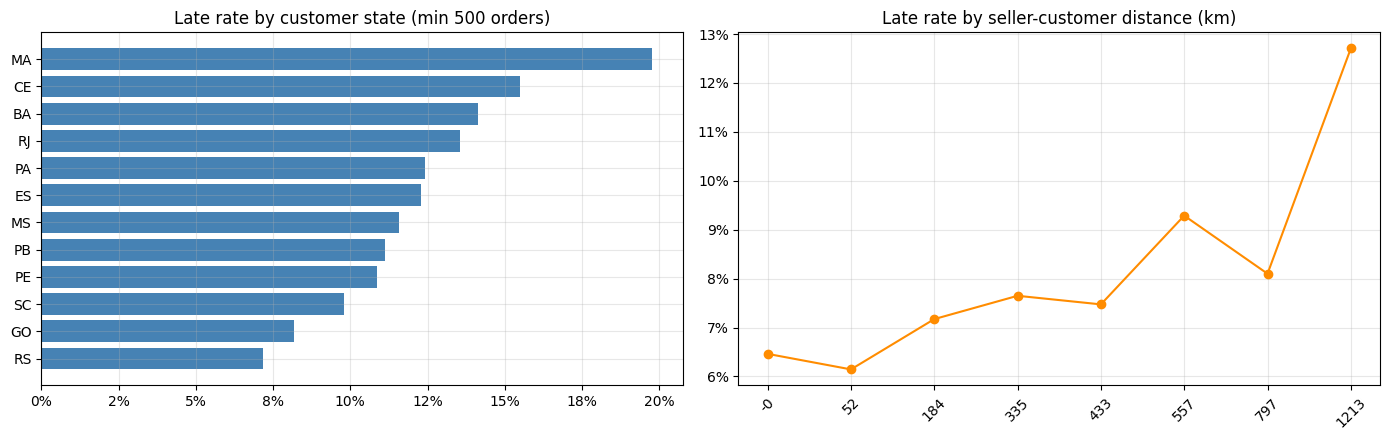

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

by_state = (
    df.groupby("customer_state")
      .agg(late_rate=(TARGET, "mean"), orders=(TARGET, "size"))
      .query("orders >= 500")
      .sort_values("late_rate", ascending=False)
      .head(12)
)
axes[0].barh(by_state.index[::-1], by_state["late_rate"][::-1], color="steelblue")
axes[0].set_title("Late rate by customer state (min 500 orders)")
axes[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

bins = pd.qcut(df["seller_customer_distance_km"], 8, duplicates="drop")
by_dist = df.groupby(bins, observed=True)[TARGET].mean()
axes[1].plot(range(len(by_dist)), by_dist.to_numpy(), marker="o", color="darkorange")
axes[1].set_xticks(range(len(by_dist)))
axes[1].set_xticklabels([f"{i.left:.0f}" for i in by_dist.index], rotation=45)
axes[1].set_title("Late rate by seller-customer distance (km)")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

plt.tight_layout()
plt.show()

## 4. Modelling design

### 4.1 Temporal split

A random split lets the model train on December and be tested on November. It
then scores well by memorising which months had high late rates — information
deployment never provides. Train is everything through April 2018; test is
everything after.

In [18]:
train, test = pipeline.temporal_split(df)

### 4.2 Two prediction scenarios

A feature can be present in the training data and still be unavailable at the
moment you need to predict.

| Scenario | Available | Intervention possible |
|---|---|---|
| `pre_dispatch` | Everything known when the order is placed | Expedite dispatch, re-route, warn the customer |
| `post_dispatch` | Adds carrier-handover timing | Escalate a parcel already in transit |

`carrier_pickup_days` requires the carrier to have already collected the
parcel. A pre-dispatch model that uses it cannot run when it is needed. This
separation is enforced in code and asserted in tests.

In [19]:
pre_cols = pipeline.feature_columns(df, "pre_dispatch")
post_cols = pipeline.feature_columns(df, "post_dispatch")
print(f"pre_dispatch : {len(pre_cols)} features")
print(f"post_dispatch: {len(post_cols)} features")
print(f"difference   : {sorted(set(post_cols) - set(pre_cols))}")

pre_dispatch : 62 features
post_dispatch: 63 features
difference   : ['carrier_pickup_days']


## 5. Results

### 5.1 The 2x2 ablation

Two design choices, crossed: seller/route history features, and probability
calibration. Each cell is a full fit and forward-tested evaluation.

In [20]:
results = {}
for use_history in (False, True):
    for calibrate in (False, True):
        cols = pipeline.feature_columns(df, "pre_dispatch", use_history=use_history)
        pipe = pipeline.build_pipeline(train, cols, "logistic_regression", y=train[TARGET])
        if calibrate:
            model = pipeline.fit_calibrated(pipe, train, cols)
        else:
            pipe.fit(train[cols], train[TARGET])
            model = pipe
        proba = model.predict_proba(test[cols])[:, 1]
        label = f"history={use_history}, calibrated={calibrate}"
        results[label] = evaluate.evaluate(test[TARGET].to_numpy(), proba, CONFIG.cost, label)

ablation = evaluate.comparison_table(list(results.values()))
ablation[["roc_auc", "average_precision", "brier", "chosen_threshold",
          "recall_at_chosen", "savings_vs_no_model", "recall_at_20pct_budget"]]

,roc_auc,average_precision,brier,chosen_threshold,recall_at_chosen,savings_vs_no_model,recall_at_20pct_budget
model,,,,,,,
"history=False, calibrated=False",0.7203,0.1356,0.2798,0.8260,0.1671,1616.0,0.4272
"history=False, calibrated=True",0.7395,0.1519,0.0596,0.2325,0.2753,3295.0,0.4570
"history=True, calibrated=False",0.7276,0.1393,0.2552,0.8386,0.1266,1812.0,0.4361
"history=True, calibrated=True",0.7410,0.1543,0.0601,0.2876,0.1924,3328.0,0.4703


> **How to read this table — the ablation results**
>
> Each row is one model variant. The columns measure different things:
>
> | Metric | What it measures | Higher is better? |
> |---|---|---|
> | **ROC AUC** | How well the model *ranks* risky orders above safe ones — 0.5 is random, 1.0 is perfect | Yes |
> | **Average precision** | How useful the model is when you can only act on a limited budget — it rewards catching late orders early in the ranking | Yes |
> | **Brier score** | How accurate the probability numbers are — a Brier of 0 is perfect, 0.25 is no better than predicting the mean for every order | **No — lower is better** |
> | **Chosen threshold** | The probability cutoff at which we decide to flag an order for action — not 0.5, but cost-derived | — |
> | **Recall at chosen** | Of all the orders that actually arrived late, what share does the model flag at this threshold | Yes |
> | **Savings vs no model** | Extra money saved (in BRL) compared to doing nothing — the operational bottom line | Yes |
> | **Recall at 20% budget** | If you can only act on 20% of orders, how many of the truly late ones do you catch | Yes |
>
> **The headline finding:** calibration (rightmost two models) roughly doubles the savings and cuts the Brier score by a factor of four, while barely touching AUC. This is the paper's Section 6 claim — that calibration is load-bearing — measured rather than assumed.

**Reading the ablation.**

Calibration is the dominant effect. It leaves the ranking untouched — Platt
scaling is strictly monotone, so AUC barely moves — yet the Brier score falls
by roughly a factor of four and modelled savings roughly double.

The mechanism is the decision threshold. SMOTE trains the classifier on an
artificially balanced world; on a problem with a ~6% base rate its raw outputs
are inflated, and the cost-optimal cutoff has to climb above 0.8 to compensate.
After calibration the cutoff sits near the base rate where it belongs.

**This is the paper's Section 6 claim, measured.** The paper states that
calibration is "load-bearing rather than optional" for the BLL. An
uncalibrated model would display ~0.84 where the honest figure is ~0.23 —
and the BLL multiplies that number by an order value to produce a confident
monetary recommendation.

History features help, but marginally. That is worth reporting honestly: the
hypothesis was that a seller's past dispatch record would predict the next
order's lateness, and the measured contribution is small.

### 5.2 Scenario comparison — the operational finding

In [22]:
scenario_results = []
models = {}
for scenario, cols in [("pre_dispatch", pre_cols), ("post_dispatch", post_cols)]:
    model = pipeline.fit_calibrated(
        pipeline.build_pipeline(train, cols, "logistic_regression", y=train[TARGET]),
        train, cols,
    )
    proba = model.predict_proba(test[cols])[:, 1]
    scenario_results.append(evaluate.evaluate(test[TARGET].to_numpy(), proba, CONFIG.cost, scenario))
    models[scenario] = (model, cols)

scenarios = evaluate.comparison_table(scenario_results)
scenarios[["roc_auc", "average_precision", "recall_at_chosen", "precision_at_chosen",
           "savings_vs_no_model", "recall_at_20pct_budget"]]

,roc_auc,average_precision,recall_at_chosen,precision_at_chosen,savings_vs_no_model,recall_at_20pct_budget
model,,,,,,
pre_dispatch,0.7410,0.1543,0.1924,0.2216,3328.0,0.4703
post_dispatch,0.8388,0.3484,0.5652,0.2557,11929.0,0.6715


> **How to read this table — pre-dispatch vs post-dispatch**
>
> The two rows compare what happens when you add one feature: `carrier_pickup_days` — how long the parcel took to reach the carrier after the order was placed.
>
> | Metric | Plain meaning |
> |---|---|
> | **ROC AUC** | How well the model separates late from on-time orders overall |
> | **Average precision** | Precision–recall summary — the most relevant metric when positive cases are rare (8% base rate here) |
> | **Recall at chosen** | Of orders that actually went late, what share does the model catch at its operating threshold |
> | **Precision at chosen** | Of orders the model flags, what share actually went late — the false-alarm rate |
> | **Savings vs no model** | Operational value added in BRL over doing nothing |
> | **Recall at 20% budget** | Best-case catch rate if you can only chase 20% of flagged orders |
>
> **The key finding:** the post-dispatch model is substantially stronger on every measure, driven almost entirely by `carrier_pickup_days`. This means lateness at Olist is primarily a *dispatch* problem — how quickly the seller hands the parcel to the carrier — not a routing or geography problem. The product implication is a dispatch monitor, not an order-time risk score.

**The case study's main operational conclusion.**

The two scenarios differ by essentially one feature: how long the parcel took
to reach the carrier. That single column moves AUC substantially and
multiplies modelled savings.

Read as a business statement rather than a modelling one: **lateness at Olist
is a dispatch problem, not a routing problem.** Very little that is knowable
at checkout predicts it well; how quickly the seller hands the parcel over
predicts it strongly.

The product implication is therefore not an order-time risk score but a
**dispatch monitor** that escalates when a seller is slow to hand off. In BLL
terms this is a *recommend*-level output — the kind of conclusion the
framework claims to produce and that SHAP attributions alone cannot.

### 5.3 Choosing the operating point

The default 0.5 threshold assumes a false positive and a false negative cost
the same. Here they plainly do not. The threshold below minimises expected
cost; the flat line is the do-nothing baseline. A model whose curve never dips
below that line is not worth deploying at these cost assumptions.

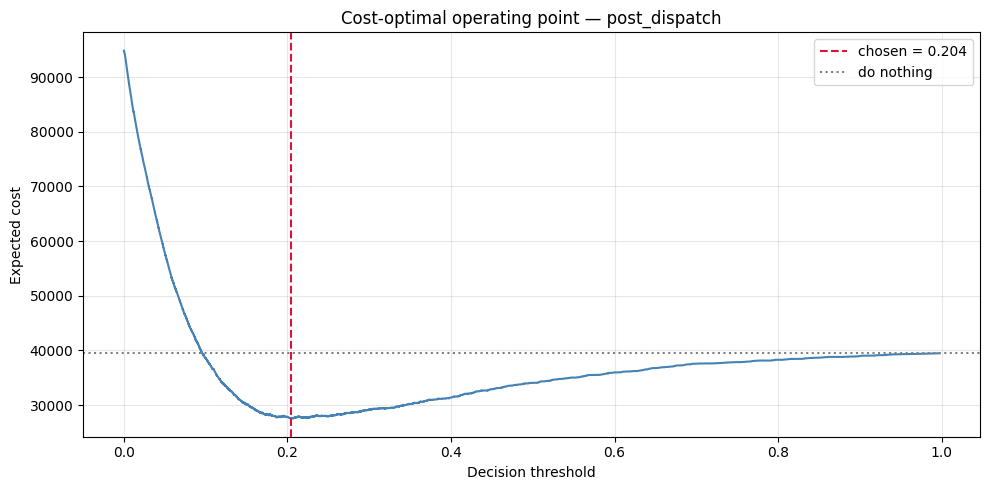

In [23]:
best = max(scenario_results, key=lambda r: r["metrics"]["savings_vs_no_model"])
curve = best["cost_curve"]

fig, ax = plt.subplots()
ax.plot(curve["threshold"], curve["expected_cost"], color="steelblue")
ax.axvline(best["threshold"]["threshold"], color="crimson", ls="--",
           label=f"chosen = {best['threshold']['threshold']:.3f}")
ax.axhline(best["threshold"]["baseline_cost"], color="grey", ls=":", label="do nothing")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Expected cost")
ax.set_title(f"Cost-optimal operating point — {best['metrics']['model']}")
ax.legend()
plt.tight_layout()
plt.show()

### 5.4 What the model actually uses

Permutation importance on the held-out set, not impurity-based importance.
Impurity importance is biased toward high-cardinality continuous features,
which is how coordinates and product dimensions end up outranking real signal.

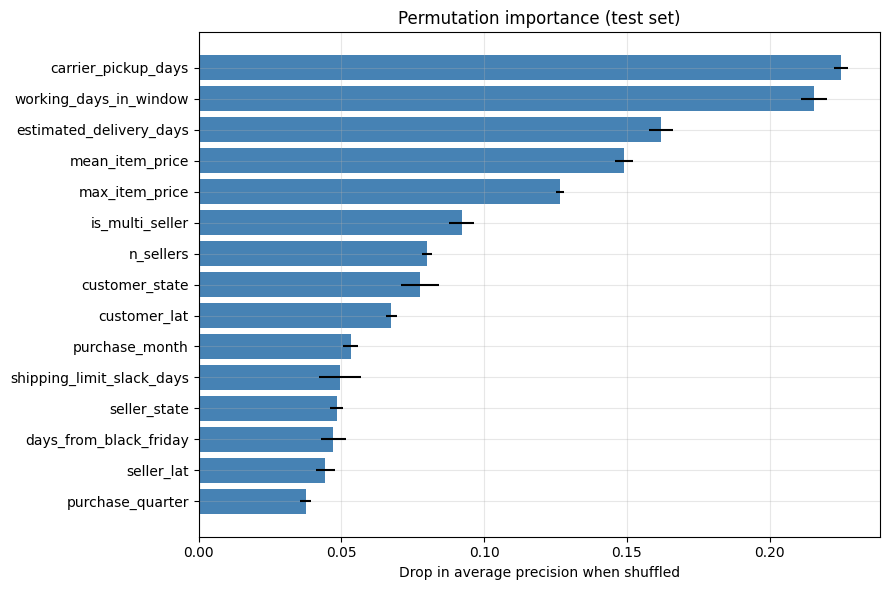

In [24]:
from sklearn.inspection import permutation_importance

model, cols = models["post_dispatch"]
perm = permutation_importance(
    model, test[cols], test[TARGET], n_repeats=5,
    random_state=RANDOM_STATE, scoring="average_precision", n_jobs=-1,
)
importance = (
    pd.DataFrame({"feature": cols, "importance": perm.importances_mean,
                  "std": perm.importances_std})
    .sort_values("importance", ascending=False)
)

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="steelblue")
ax.set_xlabel("Drop in average precision when shuffled")
ax.set_title("Permutation importance (test set)")
plt.tight_layout()
plt.show()

> **How to read the feature importance chart**
>
> Each bar shows how much the model's **average precision** drops when that feature's values are randomly shuffled across all test orders. A big drop means the model relies heavily on that feature; a drop near zero means it contributes little.
>
> Key things to notice:
>
> - **Why permutation importance, not impurity importance?** The default importance in tree models (`feature_importances_`) favours high-cardinality continuous features like distance and weight even when they carry little signal. Permutation importance is measured on the held-out test set, so it reflects genuine out-of-sample contribution.
> - **Error bars** show variance across the 5 random shuffles — wide bars mean the estimate is noisy.
> - **`carrier_pickup_days` appearing near the top** is the same finding as the scenario comparison above: dispatch speed dominates.
> - **Calendar features** (month, quarter, purchase hour) appearing lower than in Cecilia's notebook confirms the temporal split is working — the model is no longer memorising which weeks had high late rates.

## 6. The Business Language Layer

Everything above produces a probability. The BLL turns that probability into
a decision. The layer reads the model's explanation; it does not retrain or
replace the model.

### 6.1 What SHAP returns — the translation gap

This is the paper's Figure 3: technically complete, operationally silent.

In [25]:
model, cols = models["post_dispatch"]
risk = model.predict_proba(test[cols])[:, 1]

print(f"Calibrated risk range across {len(risk):,} test orders: "
      f"{risk.min():.1%} to {risk.max():.1%}")
print(f"Median {np.median(risk):.1%} · 90th percentile {np.percentile(risk, 90):.1%} "
      f"· 99th percentile {np.percentile(risk, 99):.1%}")

idx = int(risk.argmax())
row = test[cols].iloc[[idx]]
order_value = float(test["total_price"].iloc[idx])
order_id = test["order_id"].iloc[idx]

explanation = bll.explain_order(model, row, background=train[cols].head(300))
drivers = explanation.top_drivers(6)
print("\nSHAP local explanation — what the explainer returns:\n")
print(drivers.round(4).to_string())

Calibrated risk range across 25,288 test orders: 0.0% to 99.7%
Median 7.0% · 90th percentile 24.3% · 99th percentile 57.1%



SHAP local explanation — what the explainer returns:

carrier_pickup_days          7.9221
working_days_in_window       1.3132
shipping_limit_slack_days   -1.2240
estimated_delivery_days      1.1163
purchase_year                0.9527
purchase_month               0.8364


> **How to read the calibrated risk range**
>
> These numbers describe the distribution of predicted late-delivery probabilities across the 25,288 test orders:
>
> - **Median 7.0%** — half of orders have a risk below this. It sits close to the 8.14% base rate, which is a sign the model is calibrated: it doesn't push most orders far from the overall average without evidence.
> - **90th percentile 24.3%** — only 1 in 10 orders is flagged above this level. This is the realistic upper range for a typical high-risk order.
> - **99th percentile 57.1%** — genuine extreme cases, less than 1 in 100 orders.
> - **Maximum 99.7%** — the single most extreme order in the test set. This is the one shown in the decision brief below. Note: for a paper figure, a 90th-percentile order (around 24%) is more representative than the maximum.
>
> **Why this matters for the BLL:** the paper's Figure 5 uses 71% as an illustrative value. Your real model produces probabilities in that range (57–100% at the top 1%) — so the figures are reachable, but they represent rare extreme orders, not the typical case.

The numbers above are correct and unreadable. None of them tells an
operations lead whether to ship the order, what it will cost, or which of
several thousand open orders to call first.

### 6.2 What the BLL returns from the same evidence

This is the paper's Figure 5 and Figure 6, generated rather than designed.
The evidence is identical; the register, the resolution, and the intended
reader are not.

In [26]:
costs = BusinessCostModel(currency="BRL", refund_share=0.42,
                          churn_share=0.46, support_cost=12.0, intervention_cost=4.0)

precision = scenarios.loc["post_dispatch", "precision_at_chosen"]
brief = bll.build_brief(model, row, explanation, order_value=order_value,
                        costs=costs, model_precision=float(precision), order_id=order_id)

print(bll.render_text(brief))

DELIVERY RISK ASSESSMENT — order 4505acb3759da6b9c7d79a80d29ab3bb
Late-delivery probability : 99.7%  (High risk)
Order value               : BRL 30

KEY CONTRIBUTING FACTORS
  [Adds risk  ] Time to carrier handover
                  This parcel is slow leaving the warehouse.
  [Adds risk  ] Working days available
                  Few working days fall inside the promised window.
  [Lowers risk] Dispatch deadline slack
                  There is comfortable margin between the dispatch deadline and the promise.
  [Adds risk  ] Delivery promise length
                  The promised window is tight for this route, leaving little slack for delay.

WHAT THIS MEANS
  - The delivery promise to this customer is likely to be missed.
  - Expect a review-score drop and an inbound support contact if no action is taken.
  - BRL 38 of customer value is exposed on this order.

BUSINESS IMPACT IF LATE
  Refund exposure                    BRL 13
  Repeat-purchase risk               BRL 14
  Support cos

### 6.3 Traceability

The paper requires that every business statement trace back to its originating
attribution. `DecisionBrief.audit()` returns that mapping.

In [27]:
brief.audit()

,statement,feature,feature_value,shap_value,direction
0,This parcel is slow leaving the warehouse.,carrier_pickup_days,36.219456,7.922070,raises
1,Few working days fall inside the promised window.,working_days_in_window,8.394132,1.313232,raises
2,There is comfortable margin between the dispat...,shipping_limit_slack_days,3.385579,-1.223993,lowers
3,"The promised window is tight for this route, l...",estimated_delivery_days,10.394132,1.116260,raises


### 6.4 Scenario simulation — the *what if* rung

Counterfactuals run the full deployed pipeline rather than approximating from
SHAP values, so the figures shown are the system's own output.

Note what levers are offered. Olist records no courier tier, so no
courier-upgrade option is available — the interventions are the ones the data
supports: dispatch speed and promise length. Offering a lever the model cannot
evaluate would produce a recommendation with nothing behind it.

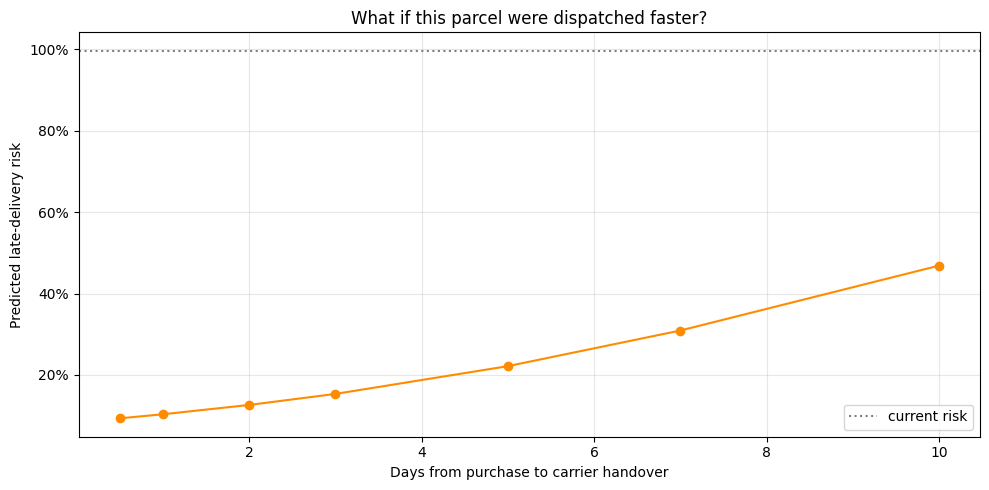

,carrier_pickup_days,predicted_risk
0,0.5,0.0932
1,1.0,0.1032
2,2.0,0.1261
3,3.0,0.1532
4,5.0,0.2215
5,7.0,0.3091
6,10.0,0.4687


In [28]:
sweep = []
for days in [0.5, 1, 2, 3, 5, 7, 10]:
    sweep.append({
        "carrier_pickup_days": days,
        "predicted_risk": bll.counterfactual(model, row, "carrier_pickup_days", days),
    })
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots()
ax.plot(sweep["carrier_pickup_days"], sweep["predicted_risk"], marker="o", color="darkorange")
ax.axhline(brief.probability, color="grey", ls=":", label="current risk")
ax.set_xlabel("Days from purchase to carrier handover")
ax.set_ylabel("Predicted late-delivery risk")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("What if this parcel were dispatched faster?")
ax.legend()
plt.tight_layout()
plt.show()

sweep.round(4)

### 6.5 Sensitivity to the cost assumptions

The monetary figures are **assumptions, not measured Olist finances**. The
recommendation is a function of those numbers as much as of the model, so the
paper's own standard requires showing how it moves when they change.

In [29]:
sensitivity = []
for refund in (0.2, 0.42, 0.7):
    for churn in (0.2, 0.46, 0.8):
        c = BusinessCostModel(currency="BRL", refund_share=refund, churn_share=churn,
                              support_cost=12.0, intervention_cost=4.0)
        b = bll.build_brief(model, row, explanation, order_value=order_value, costs=c)
        sensitivity.append({
            "refund_share": refund,
            "churn_share": churn,
            "exposure": b.exposure,
            "recommendation": b.recommendation.name,
            "net_saving": b.net_saving,
        })

pd.DataFrame(sensitivity).round(2)

,refund_share,churn_share,exposure,recommendation,net_saving
0,0.20,0.20,24.00,Expedite dispatch,17.45
1,0.20,0.46,31.79,Expedite dispatch,24.42
2,0.20,0.80,41.99,Expedite dispatch,33.53
3,0.42,0.20,30.59,Expedite dispatch,23.35
4,0.42,0.46,38.39,Expedite dispatch,30.31
5,0.42,0.80,48.59,Expedite dispatch,39.43
6,0.70,0.20,38.99,Expedite dispatch,30.85
7,0.70,0.46,46.79,Expedite dispatch,37.82
8,0.70,0.80,56.98,Expedite dispatch,46.93


## 7. Export the deployable model

Everything above ran in memory. This section selects the model to ship, saves
it as a single artefact, and bundles it for Streamlit Community Cloud.

**One artefact, not five.** The saved object contains the preprocessing,
resampling, classifier and calibrator in a single pipeline, plus the feature
list and decision threshold. Nothing has to be kept in sync at serving time —
which is what removes the class of deployment bug where a scaler and a model
disagree about column order.


In [30]:
import json
import sys

import joblib

from olist.config import MODELS_DIR

# Selection is by expected business cost, not AUC. A model that ranks well but
# cannot be operated at a profitable threshold is not the one to deploy.
costs_by_scenario = {r["metrics"]["model"]: r for r in scenario_results}
best_scenario = min(costs_by_scenario, key=lambda k: costs_by_scenario[k]["metrics"]["cost_per_order"])
best_result = costs_by_scenario[best_scenario]
best_model, best_cols = models[best_scenario]

artefact = {
    "pipeline": best_model,
    "model_name": "logistic_regression",
    "scenario": best_scenario,
    "feature_columns": best_cols,
    "threshold": best_result["threshold"]["threshold"],
    "trained_at": pd.Timestamp.now("UTC").isoformat(),
    "metrics": {k: float(v) for k, v in best_result["metrics"].items()
                if isinstance(v, (int, float, np.floating))},
    "environment": {
        "python": sys.version.split()[0],
        "scikit-learn": __import__("sklearn").__version__,
        "xgboost": __import__("xgboost").__version__,
        "imbalanced-learn": __import__("imblearn").__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}

MODELS_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODELS_DIR / f"model_{best_scenario}.joblib"
joblib.dump(artefact, model_path)

print(f"Selected  : {best_scenario}")
print(f"Threshold : {artefact['threshold']:.4f}")
print(f"Features  : {len(best_cols)}")
print(f"Saved to  : {model_path}")
print(json.dumps(artefact["environment"], indent=2))

Selected  : post_dispatch
Threshold : 0.2039
Features  : 63
Saved to  : /content/olist/models/model_post_dispatch.joblib
{
  "python": "3.12.13",
  "scikit-learn": "1.6.1",
  "xgboost": "3.3.0",
  "imbalanced-learn": "0.14.2",
  "pandas": "2.2.2",
  "numpy": "2.0.2"
}


### 7.1 Round-trip check

Reload the saved file and score real rows. A pickle that cannot be reloaded
fails here, in ten seconds, rather than on the deployment server.

**Pickles are version-sensitive.** The environment recorded above must be
pinned wherever this runs, or scikit-learn may load the object with altered
behaviour rather than refusing outright.


In [31]:
reloaded = joblib.load(model_path)
sample = test[reloaded["feature_columns"]].tail(500)

proba = reloaded["pipeline"].predict_proba(sample)[:, 1]
flagged = int((proba >= reloaded["threshold"]).sum())

print(f"Scored {len(proba)} orders")
print(f"Mean risk {proba.mean():.1%} · flagged {flagged} ({flagged / len(proba):.1%})")
print(f"Round-trip OK — predictions match: "
      f"{np.allclose(proba, best_model.predict_proba(sample)[:, 1])}")

Scored 500 orders
Mean risk 10.3% · flagged 64 (12.8%)
Round-trip OK — predictions match: True


### 7.2 Sample orders for the demo

Streamlit Community Cloud has a 1 GB memory limit and no access to the raw
CSVs. Shipping a small sample of scored orders lets the deployed app show real
decision briefs without carrying the full 96k-row feature table.


In [32]:
SAMPLE_SIZE = 300

risk_all = best_model.predict_proba(test[best_cols])[:, 1]
ranked = test.assign(_risk=risk_all).sort_values("_risk", ascending=False)

# Stratified across the risk range: a demo showing only high-risk orders would
# misrepresent what the model does on a typical day.
sample_orders = pd.concat([
    ranked.head(SAMPLE_SIZE // 3),                                  # highest risk
    ranked.iloc[len(ranked) // 2 : len(ranked) // 2 + SAMPLE_SIZE // 3],   # median
    ranked.tail(SAMPLE_SIZE // 3),                                  # lowest risk
]).drop(columns=["_risk"])

keep = list(dict.fromkeys(best_cols + ["order_id", "total_price", TARGET]))
sample_orders = sample_orders[[c for c in keep if c in sample_orders.columns]]

# A background sample is needed for SHAP; without it, attributions are measured
# against the rows being explained rather than a fixed reference.
background = train[best_cols].sample(200, random_state=RANDOM_STATE)

DEPLOY_DIR = pathlib.Path("deploy")
DEPLOY_DIR.mkdir(exist_ok=True)
sample_orders.to_parquet(DEPLOY_DIR / "sample_orders.parquet", index=False)
background.to_parquet(DEPLOY_DIR / "background.parquet", index=False)

print(f"{len(sample_orders)} sample orders, {len(background)} background rows")
print(f"Risk range in sample: {best_model.predict_proba(sample_orders[best_cols])[:, 1].min():.1%} "
      f"to {best_model.predict_proba(sample_orders[best_cols])[:, 1].max():.1%}")

300 sample orders, 200 background rows
Risk range in sample: 0.0% to 99.7%


### 7.3 Build the deployment bundle

Produces a self-contained folder that can be pushed to a GitHub repository and
pointed at Streamlit Community Cloud.


In [33]:
import shutil

shutil.copy(model_path, DEPLOY_DIR / model_path.name)

# The app imports the olist package, so it travels with the bundle.
pkg_dest = DEPLOY_DIR / "src" / "olist"
shutil.rmtree(DEPLOY_DIR / "src", ignore_errors=True)
shutil.copytree(pathlib.Path("src") / "olist", pkg_dest,
                ignore=shutil.ignore_patterns("__pycache__"))

shutil.copy(pathlib.Path("app") / "cloud_app.py", DEPLOY_DIR / "streamlit_app.py")

(DEPLOY_DIR / "requirements.txt").write_text("\n".join([
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
    f"scikit-learn=={__import__('sklearn').__version__}",
    f"imbalanced-learn=={__import__('imblearn').__version__}",
    f"xgboost=={__import__('xgboost').__version__}",
    f"shap=={__import__('shap').__version__}",
    "joblib>=1.3",
    "workalendar>=17.0",
    "pyarrow>=14.0",
    "streamlit>=1.30",
    "",
]), encoding="utf-8")

archive = shutil.make_archive("olist_bll_deploy", "zip", DEPLOY_DIR)
print("Bundle contents:")
for p in sorted(DEPLOY_DIR.rglob("*")):
    if p.is_file() and "__pycache__" not in str(p):
        print(f"  {p.relative_to(DEPLOY_DIR)}  ({p.stat().st_size / 1024:.0f} KB)")
print(f"\nArchive: {archive} ({pathlib.Path(archive).stat().st_size / 1e6:.1f} MB)")

Bundle contents:
  background.parquet  (87 KB)
  model_post_dispatch.joblib  (3646 KB)
  requirements.txt  (0 KB)
  sample_orders.parquet  (119 KB)
  src/olist/__init__.py  (0 KB)
  src/olist/bll/__init__.py  (1 KB)
  src/olist/bll/brief.py  (15 KB)
  src/olist/bll/explain.py  (6 KB)
  src/olist/bll/glossary.py  (9 KB)
  src/olist/calendar_br.py  (6 KB)
  src/olist/cleaning.py  (15 KB)
  src/olist/config.py  (5 KB)
  src/olist/evaluate.py  (6 KB)
  src/olist/features.py  (13 KB)
  src/olist/history.py  (9 KB)
  src/olist/io.py  (4 KB)
  src/olist/pipeline.py  (16 KB)
  src/olist/train.py  (10 KB)
  src/olist/validate.py  (9 KB)
  streamlit_app.py  (8 KB)

Archive: /content/olist/olist_bll_deploy.zip (1.3 MB)


### 7.4 Download

On Colab this triggers a browser download. Locally the archive is already on
disk at the path printed above.


In [34]:
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print(f"Not on Colab — the bundle is at {pathlib.Path(archive).resolve()}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.5 Deploying to Streamlit Community Cloud

1. Create a **public** GitHub repository.
2. Unzip the bundle and commit its contents to the repository root, so that
   `streamlit_app.py` and `requirements.txt` sit at the top level.
3. At [share.streamlit.io](https://share.streamlit.io), choose **New app**,
   select the repository, and set the main file to `streamlit_app.py`.

The bundle carries the model, a sample of scored orders, and the `olist`
package, so the app needs no raw data at run time.

**Two constraints worth knowing before you deploy.** Community Cloud gives
roughly 1 GB of memory, and SHAP is the heavy step — the app computes
explanations for one order at a time rather than in batch for that reason.
And the repository must be public, so the sample data becomes public with it;
the Olist dataset is openly licensed, but confirm that is acceptable to your
team before pushing.


## 8. Limitations

Stated plainly, because a fluent costed recommendation reads as more
authoritative than its evidence supports — the risk the paper itself
identifies in Section 6.

1. **Cost parameters are assumed, not measured.** Every monetary figure
   inherits that assumption. The sensitivity table above shows the range.

2. **SHAP explains the base classifier's decision function; the displayed
   number is the calibrated probability.** These are related by a monotone
   map, not identical. Attributions are contributions to the risk *ranking*,
   not an additive decomposition of the percentage on screen.

3. **Precision at the operating point is modest.** The model ranks a limited
   alert budget usefully; the score for any individual order is weak evidence.

4. **`estimated_delivery_days` is partly tautological.** The target is defined
   relative to the estimate, so a longer promise mechanically lowers late
   risk. This is a lever Olist controls: on-time performance can be bought
   with more conservative estimates, at some cost to conversion.

5. **No causal claim.** Counterfactuals are the model's answer under a
   ceteris-paribus assumption. Dispatching faster in reality may correlate
   with changes the model cannot see. An intervention policy built on this
   should be validated by a holdout experiment.

6. **The data ends in October 2018** and is Brazilian. Carrier networks
   change; nothing here should be assumed to hold in another market today.

7. **Right-censoring is handled but not eliminated.** The 30-day buffer is a
   judgement call, not a derived quantity.

## 9. What this contributes to the paper

| Paper element | Status before | Status now |
|---|---|---|
| Figure 5 (live decision surface) | Mockup, exemplary values | Generated from a trained model |
| Figure 6 (translation in practice) | Mockup | Real SHAP output, real options table |
| Calibration as "load-bearing" (§6) | Asserted | Measured — see the 2x2 ablation |
| Domain-agnostic claim | Argued | Glossary is separable; porting = new glossary |
| Traceability (§6, future work) | Proposed | Implemented in `DecisionBrief.audit()` |

The scenario comparison also supplies a substantive operational finding the
mockups do not contain: the intervention point is dispatch, not order time.